# Clusterização de reclamações de clientes com HDBSCAN e K-means

**Objetivo:** organizar reclamações de clientes em grupos de problemas parecidos, separar o que é ruído e achar a **reclamação mais representativa** de cada grupo, que pode orientar o time de atendimento ou alimentar um agente de IA.

**Dados:** 1.620 reclamações **sintéticas** de clientes de uma loja online em 6 temas, mais mensagens genéricas que funcionam como ruído (`src/gerar_textos.py`). Nenhum dado real é usado. O tema real só é usado no fim, para avaliar o resultado.

**Por que não supervisionado:** no mundo real não existe rótulo dizendo de que tipo é cada reclamação.

**Roteiro**
1. Transformar texto em vetores (TF-IDF + SVD, a ideia de *embeddings*)
2. **HDBSCAN** para descobrir quantos grupos existem e separar o ruído
3. **K-means** para chegar aos centroides e à reclamação mais representativa
4. Avaliar e interpretar os grupos

In [1]:
import sys; sys.path.insert(0, 'src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gerar_textos import gerar_textos, CANAIS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.manifold import TSNE
SEED = 42
df = gerar_textos()
print(df.shape)
df.sample(8, random_state=1)

(1620, 2)


,descricao,tema_real
1162,senha nao aceita na minha conta via site ja re...,acesso_conta
1296,estorno nao realizado no boleto via android,cobranca_indevida
301,produto diferente do anunciado no pedido receb...,produto_defeito
167,favor retornar ja reclamei antes,ruido
1094,peca faltando na compra via site urgente,produto_defeito
1352,elogio ao servico pela segunda vez,ruido
553,atendente nao resolveu no chat via ios pela se...,atendimento
1159,erro ao abrir na tela inicial via telefone des...,app_travando


## 1. Texto em vetores

Uso **TF-IDF** com palavras e pares de palavras, removendo palavras vazias, palavras de urgência e o canal de contato (que dizem *como* e *por onde* o cliente reclamou, não *do que* reclamou), e reduzo para 10 dimensões com **SVD** (análise semântica latente). Cada reclamação vira um vetor denso, em que textos com significado parecido ficam próximos. Normalizo os vetores para que a distância euclidiana se comporte como a **similaridade de cosseno**.

> Em produção, este passo pode usar embeddings de um modelo de linguagem (por exemplo, `sentence-transformers`). O resto do pipeline continua igual.

In [2]:
STOP = ['de', 'do', 'da', 'no', 'na', 'nas', 'nos', 'em', 'o', 'a', 'os', 'as', 'ao', 'para', 'com', 'por', 'e',
        'um', 'uma', 'apos', 'acima', 'desde', 'dos', 'das', 'via', 'minha', 'meu',
        # palavras de urgência e insistência: dizem como o cliente está, não do que ele reclama
        'ja', 'reclamei', 'antes', 'preciso', 'ajuda', 'pela', 'segunda', 'vez', 'ontem', 'muito', 'insatisfeito', 'urgente'] + CANAIS
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words=STOP)
X_tfidf = tfidf.fit_transform(df['descricao'])
svd = TruncatedSVD(n_components=10, random_state=SEED)
X = normalize(svd.fit_transform(X_tfidf))
print(f"Vocabulário: {X_tfidf.shape[1]} termos | vetores: {X.shape}")
print(f"Variância explicada pelo SVD: {svd.explained_variance_ratio_.sum():.1%}")

Vocabulário: 319 termos | vetores: (1620, 10)
Variância explicada pelo SVD: 25.3%


## 2. HDBSCAN: quantos grupos existem?
O HDBSCAN não precisa que eu informe o número de grupos, aceita grupos de formatos diferentes e marca como ruído (`-1`) o que não pertence a nenhum grupo.

In [3]:
hdb = HDBSCAN(min_cluster_size=80, min_samples=10, copy=True)
df['grupo_hdbscan'] = hdb.fit_predict(X)
n_grupos = df.loc[df['grupo_hdbscan'] >= 0, 'grupo_hdbscan'].nunique()
print(f"Grupos encontrados: {n_grupos}")
print(f"Marcados como ruído: {(df['grupo_hdbscan'] == -1).mean():.1%}")
pd.crosstab(df['tema_real'], df['grupo_hdbscan'])

Grupos encontrados: 8
Marcados como ruído: 14.1%


grupo_hdbscan,-1,0,1,2,3,4,5,6,7
tema_real,,,,,,,,,
acesso_conta,0,0,0,0,0,0,250,0,0
app_travando,0,250,0,0,0,0,0,0,0
atendimento,72,0,0,0,0,0,0,135,43
cobranca_indevida,0,0,158,45,0,0,0,0,47
entrega,51,0,0,41,158,0,0,0,0
produto_defeito,0,0,0,0,0,250,0,0,0
ruido,106,0,0,0,0,14,0,0,0


## 3. K-means: a reclamação mais representativa
Uso o número de grupos que o HDBSCAN encontrou e rodo o K-means só nos pontos que não são ruído. A reclamação mais próxima de cada centroide é a mais representativa do grupo.

In [4]:
mask = df['grupo_hdbscan'] >= 0
km = KMeans(n_clusters=n_grupos, n_init=10, random_state=SEED).fit(X[mask])
df.loc[mask, 'grupo'] = km.labels_
df['grupo'] = df['grupo'].fillna(-1).astype(int)

termos = np.array(tfidf.get_feature_names_out())
centros_tfidf = svd.inverse_transform(km.cluster_centers_)
resumo = []
for g in range(n_grupos):
    idx = np.where(mask)[0][km.labels_ == g]
    d = np.linalg.norm(X[idx] - km.cluster_centers_[g], axis=1)
    resumo.append({'grupo': g, 'tamanho': len(idx),
                   'termos principais': ', '.join(termos[np.argsort(centros_tfidf[g])[::-1][:5]]),
                   'reclamação representativa': df.loc[idx[np.argmin(d)], 'descricao']})
pd.set_option('display.max_colwidth', 80)
pd.DataFrame(resumo).set_index('grupo')

,tamanho,termos principais,reclamação representativa
grupo,,,
0,250,"app, aplicativo, fechando sozinho, fechando, app fechando",app travando na tela inicial via whatsapp desde ontem
1,290,"produto, item, pedido, funciona, produto nao",produto com defeito no item comprado via whatsapp muito insatisfeito
2,158,"cobranca, cobranca duplicada, duplicada, reconhecida, cobranca nao",cobranca duplicada no pagamento via ios pela segunda vez
3,135,"sem, chat, suporte, sem solucao, solucao",chat encerrado sem solucao na central de ajuda via ios desde ontem
4,250,"conta, verificacao, nao, aceita, nao aceita",senha nao aceita na verificacao em duas etapas via whatsapp pela segunda vez
5,132,"entrega, rastreio parado, rastreio, parado, prazo entrega",pedido atrasado na entrega via android pela segunda vez
6,90,"nao, estorno, realizado, estorno nao, nao realizado",estorno nao realizado no boleto via ios
7,86,"errado, valor cobrado, cobrado errado, cobrado, valor",entregue no endereco errado na transportadora via android ja reclamei antes


## 4. Avaliação

In [5]:
ari = adjusted_rand_score(df.loc[mask, 'tema_real'], df.loc[mask, 'grupo'])
sil = silhouette_score(X[mask], df.loc[mask, 'grupo'])
ruido_real = df['tema_real'] == 'ruido'
pego = (df.loc[ruido_real, 'grupo_hdbscan'] == -1).mean()
falso_ruido = (df.loc[~ruido_real, 'grupo_hdbscan'] == -1).mean()
print(f"Adjusted Rand Index (grupos x tema real): {ari:.3f}")
print(f"Silhouette: {sil:.3f}")
print(f"Mensagens genéricas marcadas como ruído: {pego:.1%}")
print(f"Reclamações reais marcadas como ruído: {falso_ruido:.1%}")

Adjusted Rand Index (grupos x tema real): 0.817
Silhouette: 0.596
Mensagens genéricas marcadas como ruído: 88.3%
Reclamações reais marcadas como ruído: 8.2%


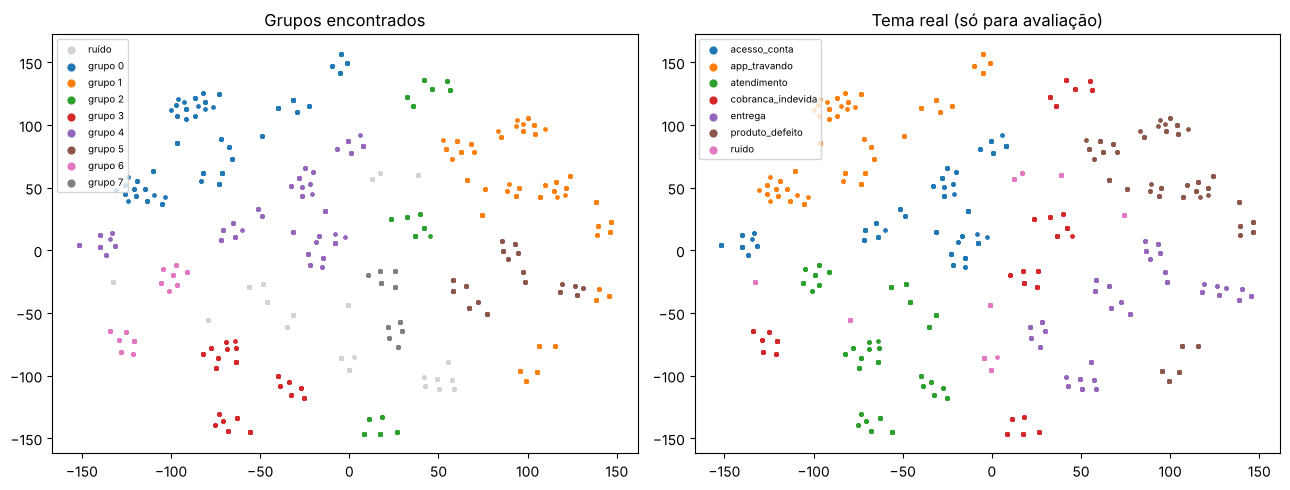

In [6]:
emb2 = TSNE(n_components=2, random_state=SEED, init='pca', perplexity=40).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for g in sorted(df['grupo'].unique()):
    m = df['grupo'] == g
    ax[0].scatter(emb2[m, 0], emb2[m, 1], s=6, c='lightgray' if g == -1 else None, label='ruído' if g == -1 else f'grupo {g}')
ax[0].set_title('Grupos encontrados'); ax[0].legend(fontsize=7, markerscale=2)
for t in sorted(df['tema_real'].unique()):
    m = df['tema_real'] == t
    ax[1].scatter(emb2[m, 0], emb2[m, 1], s=6, label=t)
ax[1].set_title('Tema real (só para avaliação)'); ax[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

## Conclusões

- O **HDBSCAN** descobriu sozinho o número de grupos e separou as mensagens genéricas como ruído.
- O **K-means** sobre os pontos não ruidosos deu os centroides e a **reclamação mais representativa** de cada grupo, que resume bem aquele tipo de problema para o time de atendimento.
- Cada algoritmo responde a uma pergunta: o HDBSCAN diz *quais grupos existem* e o K-means diz *quem representa cada um*.

**Limitações e próximos passos**
- Textos sintéticos são mais limpos que os reais. Em dados reais, vale tratar abreviações, gírias, erros de digitação e emojis.
- Trocar TF-IDF + SVD por embeddings de um modelo de linguagem para capturar sinônimos.
- Validar os grupos com o time de atendimento e acompanhar o surgimento de grupos novos com o tempo.